In [1]:
import keypoint_moseq as kpms
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

In [2]:
from jax_moseq.utils import set_mixed_map_iters
set_mixed_map_iters(64)

In [3]:
# inspect_jonathan_amph.py
import sys
import pickle
import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================
# 1. Repo Discovery (Your Code)
# ==========================================
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

PKG_PARENT = REPO_ROOT.parent
if str(PKG_PARENT) not in sys.path:
    sys.path.insert(0, str(PKG_PARENT))

# ==========================================
# 2. Load the Pickle
# ==========================================
PKL_FILENAME = "/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_amph_sessions.pkl"
pkl_path = start / PKL_FILENAME

print(f"--- Inspecting: {pkl_path} ---")

if not pkl_path.exists():
    print(f"ERROR: File not found at {pkl_path}")
    sys.exit(1)

with open(pkl_path, "rb") as f:
    sessions = pickle.load(f)

n_total = len(sessions)
print(f"Total Sessions Loaded: {n_total}")

--- Inspecting: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_amph_sessions.pkl ---
Total Sessions Loaded: 30


In [4]:
import os

# 1. Environment Tweaks (Prevents Memory Fragmentation)
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"

In [5]:
PROJECT_DIR = "amph_project"
DETECTOR = "deeplabcut"
SUBROUTINE = "jonathan"
CAM = "center_cam"          # or "side_cam"
DO_CALIBRATION = True       # flip on when you want the widget
VIDEO_EXTENSION_OVERRIDE = None  # e.g. "mkv" if not mp4/avi/mov
P_THRESH = 0.9
FRAC_MIN_PARTS = 0.4
SMOOTH_WIN = 7
ENTER_T = 0.65
EXIT_T = 0.45
OFF_GRACE = 6
MIN_ON = 10
MIN_OFF = 6

In [6]:
import keypoint_moseq as kpms

In [7]:
# assume you already have `sessions` in memory
from utils.paths import ref_pairs_from_sessions

keypoint_paths, video_paths = ref_pairs_from_sessions(sessions, subroutine=SUBROUTINE, cam=CAM)
VID_DIR = str(Path(video_paths[0]).parent)
EXT = (VIDEO_EXTENSION_OVERRIDE or Path(video_paths[0]).suffix.lstrip(".").lower())

In [8]:
project_dir = PROJECT_DIR
config = lambda: kpms.load_config(project_dir)

In [9]:
coordinates, confidences, bodyparts = kpms.load_keypoints(keypoint_paths, DETECTOR)

DOWNSAMPLE = 2
NEW_FPS = 40

print(f"--- DOWNSAMPLING x{DOWNSAMPLE} ---")
# Slice dictionaries directly
coordinates = {k: v[::DOWNSAMPLE] for k, v in coordinates.items()}
confidences = {k: v[::DOWNSAMPLE] for k, v in confidences.items()}

# Update config so future calculations use 40fps logic
kpms.update_config(PROJECT_DIR, video_dir=VID_DIR, video_extension=EXT, fps=NEW_FPS)

Loading keypoints: 100%|████████████████| 30/30 [00:01<00:00, 16.15it/s]


--- DOWNSAMPLING x2 ---


In [10]:
from utils.trimming import presence_mask_from_conf

def make_masks(confidences):
    masks = {}
    for name, conf in confidences.items():
        masks[name] = presence_mask_from_conf(
            conf,
            p_thresh=P_THRESH,
            frac_min_parts=FRAC_MIN_PARTS,
            smooth_win=SMOOTH_WIN,
            enter_thresh=ENTER_T,
            exit_thresh=EXIT_T,
            off_grace_frames=OFF_GRACE,
            min_on_frames=MIN_ON,
            min_off_frames=MIN_OFF,
        )
    return masks

all_masks = make_masks(confidences)

# for k in confidences.keys():
#     # optional: visualize one example
#     name0 = k
#     y = confidences[name0].mean(axis=1)
#     t = np.arange(len(y))
#     plt.figure()
#     plt.plot(t, y, lw=1)
#     y0, y1 = plt.ylim()
#     plt.fill_between(t, y0, y1, where=~all_masks[name0], alpha=0.15, step='mid')
#     plt.title(name0); plt.ylim(y0,y1); plt.show()

In [11]:
from utils.trimming import filter_with_masks, clamp_conf_nonneg

filtered_coords, filtered_confs, video_frame_indexes = filter_with_masks(
    coordinates, confidences, all_masks, PROJECT_DIR,
    return_video_frame_indexes=True, **kpms.load_config(PROJECT_DIR)
)
clamp_conf_nonneg(filtered_confs)

# sanity for kpms calls
for k in filtered_coords:
    assert len(filtered_coords[k]) == len(video_frame_indexes[k])
    assert len(filtered_confs[k])  == len(video_frame_indexes[k])

In [12]:
DO_CALIBRATION = False

if DO_CALIBRATION:
    kpms.noise_calibration(
        PROJECT_DIR,
        filtered_coords,
        filtered_confs,
        video_frame_indexes=video_frame_indexes,
        **kpms.load_config(PROJECT_DIR)
    )

Loaded existing PCA.


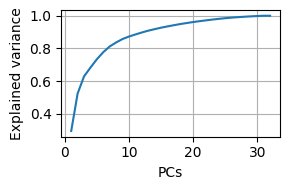

In [13]:
import gc

# ====================================================
# 7. PRE-FLIGHT PCA (CPU Subsampling)
# ====================================================
try:
    pca = kpms.load_pca(PROJECT_DIR)
    print("Loaded existing PCA.")
except Exception:
    print("Fitting new PCA (Memory Safe)...")
    # Flatten on CPU
    all_Y = np.concatenate(list(filtered_coords.values()), axis=0)
    all_C = np.concatenate(list(filtered_confs.values()), axis=0)
    
    # Sample 200k frames
    N = all_Y.shape[0]
    SAMPLE = 200000
    if N > SAMPLE:
        rng = np.random.default_rng(42)
        idx = np.sort(rng.choice(N, SAMPLE, replace=False))
        sub_Y = {"dummy": all_Y[idx]}
        sub_C = {"dummy": all_C[idx]}
    else:
        sub_Y = filtered_coords
        sub_C = filtered_confs
        
    # Load subset to GPU & Fit
    sub_data, _ = kpms.format_data(sub_Y, sub_C, **kpms.load_config(PROJECT_DIR))
    pca = kpms.fit_pca(**sub_data, **kpms.load_config(PROJECT_DIR))
    kpms.save_pca(pca, PROJECT_DIR)
    
    # Cleanup
    del sub_data, sub_Y, sub_C, all_Y, all_C
    gc.collect()
    print("PCA Saved & Memory Cleared.")

# Scree Plot
kpms.plot_scree(pca, project_dir=PROJECT_DIR)
kpms.update_config(PROJECT_DIR, latent_dim=10) # Use 12 (matches your Gold Standard output)

In [14]:
data, metadata = kpms.format_data(filtered_coords, filtered_confs, **config())

In [15]:
kpms.update_config(
    project_dir,
    sigmasq_loc=kpms.estimate_sigmasq_loc(data["Y"], data["mask"], filter_size=config()["fps"])
)

In [16]:
set_mixed_map_iters(64)

In [17]:
import jax
import jax.numpy as jnp
import numpy as np
import keypoint_moseq as kpms
from jax_moseq.models.keypoint_slds.initialize import init_states, estimate_error
from jax_moseq.models.keypoint_slds.alignment import preprocess_for_pca

def batched_init_model_by_video(data, pca, config, params_subset_size=5, batch_size=20):
    """
    Initializes a Keypoint-MoSeq model in batches to avoid GPU OOM errors.
    Includes discrete states 'z' to match standard initialization structure.
    """
    N_videos = data['Y'].shape[0]
    
    # ------------------------------------------------------------
    # STEP 1: Initialize Global Parameters (Small subset)
    # ------------------------------------------------------------
    print(f"Step 1: Initializing Params on first {params_subset_size} videos...")
    
    subset_slice = slice(0, params_subset_size)
    subset_data = {
        'Y': data['Y'][subset_slice],
        'mask': data['mask'][subset_slice],
        'conf': data['conf'][subset_slice] if 'conf' in data else None
    }
    
    # Initialize "template" model (parameters + hyperparameters)
    model = kpms.init_model(subset_data, pca=pca, **config)
    
    # ------------------------------------------------------------
    # STEP 2: Initialize States (Batched by Video)
    # ------------------------------------------------------------
    print(f"Step 2: Initializing States for {N_videos} videos (Batch size: {batch_size})...")
    
    # Extract components needed for initialization
    params = model['params']
    hypparams = model['hypparams']
    obs_hypparams = hypparams['obs_hypparams']
    seed = model['seed']
    error_estimator = config.get('error_estimator', None)
    
    # Alignment settings
    anterior_idxs = config.get('anterior_idxs')
    posterior_idxs = config.get('posterior_idxs')
    conf_threshold = config.get('conf_threshold', 0.5)
    fix_heading = config.get('fix_heading', False)

    # Storage for results. Added 'z' to capture discrete states.
    full_states = {'x': [], 'v': [], 'h': [], 's': [], 'z': []}
    
    num_batches = int(np.ceil(N_videos / batch_size))
    
    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, N_videos)
        
        # 1. Grab Batch
        Y_chunk = jnp.array(data['Y'][start_idx:end_idx])
        mask_chunk = jnp.array(data['mask'][start_idx:end_idx])
        conf_chunk = jnp.array(data['conf'][start_idx:end_idx]) if 'conf' in data else None
        
        # 2. Preprocess MANUALLY (Calculates Y_flat, v, h)
        Y_flat_chunk, v_chunk, h_chunk = preprocess_for_pca(
            Y_chunk,
            anterior_idxs=anterior_idxs,
            posterior_idxs=posterior_idxs,
            conf=conf_chunk,
            conf_threshold=conf_threshold,
            fix_heading=fix_heading,
            verbose=False 
        )

        # 3. Compute noise_prior for THIS batch
        if conf_chunk is not None and error_estimator is not None:
            batch_noise_prior = estimate_error(conf_chunk, **error_estimator)
        else:
            batch_noise_prior = 1.0

        # 4. Initialize States
        chunk_states = init_states(
            seed,
            Y_chunk,
            mask_chunk,
            params,
            batch_noise_prior,
            obs_hypparams,
            Y_flat=Y_flat_chunk, 
            v=v_chunk, 
            h=h_chunk, 
            # kwargs are consumed by preprocess_for_pca, which we skipped, so we don't pass them here
        )
        
        # 5. Offload to CPU
        # 'z' is included now. Note: 'z' length is (T - nlags), others are (T).
        for k in ['x', 'v', 'h', 's', 'z']:
            if k in chunk_states:
                full_states[k].append(jax.device_put(chunk_states[k], jax.devices('cpu')[0]))
        
        print(f"  Batch {i+1}/{num_batches} (Videos {start_idx}-{end_idx}) done.")
        
        # Cleanup
        del Y_chunk, mask_chunk, conf_chunk, Y_flat_chunk, v_chunk, h_chunk, chunk_states, batch_noise_prior

    # ------------------------------------------------------------
    # STEP 3: Stitching
    # ------------------------------------------------------------
    print("Step 3: Concatenating all states...")
    final_states = {}
    for k in ['x', 'v', 'h', 's', 'z']:
        if full_states[k]:
            final_states[k] = jnp.concatenate(full_states[k], axis=0)
            
    model['states'] = final_states
    
    # Recalculate full noise prior on CPU
    if 'conf' in data and error_estimator is not None:
        print("Recalculating full noise_prior (on CPU)...")
        with jax.default_device(jax.devices("cpu")[0]):
             model['noise_prior'] = estimate_error(jnp.array(data['conf']), **error_estimator)
    else:
        model['noise_prior'] = 1.0

    print(f"Done. State 'x' shape: {final_states['x'].shape}")
    if 'z' in final_states:
        print(f"      State 'z' shape: {final_states['z'].shape}")
        
    return model

# ================= Usage =================
model = batched_init_model_by_video(
    data, 
    pca, 
    kpms.load_config(PROJECT_DIR), 
    params_subset_size=5, 
    batch_size=20
)

Step 1: Initializing Params on first 5 videos...
Interpolating 4275 (0.5%) low-confidence keypoints
Keypoint SLDS: Initializing hyperparameters
Keypoint SLDS: Initializing noise prior
Keypoint SLDS: Initializing parameters
Keypoint SLDS: Initializing states
Step 2: Initializing States for 564 videos (Batch size: 20)...
  Batch 1/29 (Videos 0-20) done.
  Batch 2/29 (Videos 20-40) done.
  Batch 3/29 (Videos 40-60) done.
  Batch 4/29 (Videos 60-80) done.
  Batch 5/29 (Videos 80-100) done.
  Batch 6/29 (Videos 100-120) done.
  Batch 7/29 (Videos 120-140) done.
  Batch 8/29 (Videos 140-160) done.
  Batch 9/29 (Videos 160-180) done.
  Batch 10/29 (Videos 180-200) done.
  Batch 11/29 (Videos 200-220) done.
  Batch 12/29 (Videos 220-240) done.
  Batch 13/29 (Videos 240-260) done.
  Batch 14/29 (Videos 260-280) done.
  Batch 15/29 (Videos 280-300) done.
  Batch 16/29 (Videos 300-320) done.
  Batch 17/29 (Videos 320-340) done.
  Batch 18/29 (Videos 340-360) done.
  Batch 19/29 (Videos 360-380) d

In [18]:
def inspect_structure(d, indent=0):
    spacer = "  " * indent
    if isinstance(d, dict):
        for k, v in d.items():
            # If it's a nested dictionary, recurse
            if isinstance(v, dict):
                print(f"{spacer}['{k}']: <dict> with keys {list(v.keys())}")
                inspect_structure(v, indent + 1)
            # If it has a shape (JAX/NumPy array), print details
            elif hasattr(v, 'shape'):
                print(f"{spacer}['{k}']: shape={v.shape} | type={type(v).__name__}")
            # Otherwise just print the type/value summary
            else:
                val_str = str(v)
                if len(val_str) > 50: val_str = val_str[:50] + "..."
                print(f"{spacer}['{k}']: {type(v).__name__} = {val_str}")

print("--- Model Structure ---")
inspect_structure(model)

--- Model Structure ---
['seed']: shape=(2,) | type=ArrayImpl
['hypparams']: <dict> with keys ['trans_hypparams', 'ar_hypparams', 'obs_hypparams', 'cen_hypparams']
  ['trans_hypparams']: <dict> with keys ['alpha', 'gamma', 'kappa', 'num_states']
    ['alpha']: float = 5.7
    ['gamma']: float = 1000.0
    ['kappa']: float = 1000000.0
    ['num_states']: int = 100
  ['ar_hypparams']: <dict> with keys ['K_0_scale', 'S_0_scale', 'latent_dim', 'nlags', 'S_0', 'K_0', 'M_0', 'num_states', 'nu_0']
    ['K_0_scale']: float = 10.0
    ['S_0_scale']: float = 0.01
    ['latent_dim']: int = 10
    ['nlags']: int = 3
    ['S_0']: shape=(10, 10) | type=ArrayImpl
    ['K_0']: shape=(31, 31) | type=ArrayImpl
    ['M_0']: shape=(10, 31) | type=ArrayImpl
    ['num_states']: int = 100
    ['nu_0']: int = 12
  ['obs_hypparams']: <dict> with keys ['nu_s', 'nu_sigma', 'sigmasq_0', 'sigmasq_C']
    ['nu_s']: int = 5
    ['nu_sigma']: float = 100000.0
    ['sigmasq_0']: float = 0.1
    ['sigmasq_C']: float = 

Outputs will be saved to amph_project/2025_12_16-13_56_15


 50%|██████████████████▌                  | 1/2 [00:58<00:58, 58.49s/it]

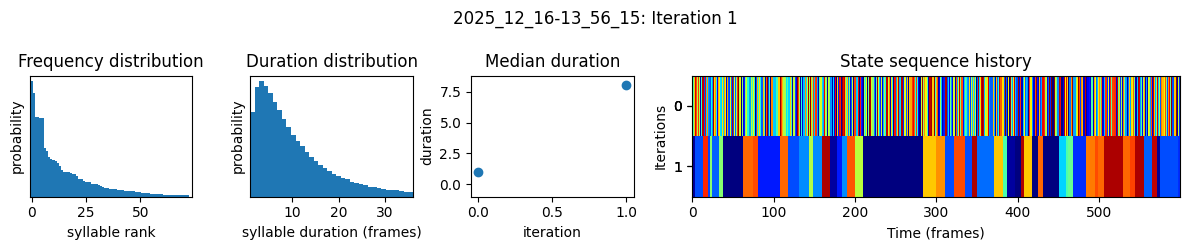

100%|█████████████████████████████████████| 2/2 [01:56<00:00, 58.09s/it]


Outputs will be saved to amph_project/2025_12_16-13_56_15


 50%|██████████████████                  | 1/2 [05:26<05:26, 326.50s/it]

In [ ]:
# model = kpms.init_model(data, pca=pca, **kpms.load_config(PROJECT_DIR))
model, model_name = kpms.fit_model(
    model, data, metadata, PROJECT_DIR,
    ar_only=True, num_iters=1, parallel_message_passing=False
)
model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR, model_name, iteration=1)
model = kpms.update_hypparams(model, kappa=1e4)
model = kpms.fit_model(
    model, data, metadata, PROJECT_DIR, model_name,
    ar_only=False, start_iter=current_iter, num_iters=current_iter+1,
    parallel_message_passing=False
)[0]